In [2]:
import sys
sys.path.append("../")

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm
from qiskit.quantum_info import Statevector, SparsePauliOp
#from qitp.engine.unitary_approximation import UnitaryApproximation
#from qitp.engine.propagation import QITEPropagation
from qitp.engine.cqite_run import cqite
#from qitp.engine.prepare_state import constraint_rotation, prepare_state, density_from_rotations, support_only
from qitp.simulation.backend import SimulatorBackend

In [4]:
from qitp.ansatz.commutator_basis import (
    CommutatorBasis
)

In [5]:
from qitp.hamiltonian import ScalableDiagHamiltonian

In [6]:
hamiltonian = ScalableDiagHamiltonian(2, gamma = 0.7)

In [17]:
dt=1e-2
nqubits = hamiltonian.num_qubits

In [19]:
d = range(0, 5)
v = range(0, 5)
trot = 2

In [21]:
energy_map = np.zeros((len(d), len(v)))
time_map   = np.zeros_like(energy_map)
basis_size = np.zeros_like(energy_map)

In [83]:
nsteps=100
target=0.4

energies=[]
fidelities=[]
errors=[]
magnetizations=[]

In [57]:
H = SparsePauliOp.from_list(hamiltonian.terms)

In [59]:
C = SparsePauliOp.from_list(hamiltonian.cterms)

In [29]:
backend = SimulatorBackend()

In [31]:
#H_eff = H + sum(Mz[1:], start=Mz[0])# + Identity

In [85]:
results = cqite(
    H,
    C,
    target,
    d[0],
    v[0],
    trot,
    dt,
    nsteps,
    backend
) 

QITE:   0%|          | 0/100 [00:00<?, ?it/s]

In [87]:
energies = results["energies"]
magnetizations = results["magnetizations"] #[np.sum(m) for m in results["magnetizations"]]
final_circuit = results["circuit"]
final_state = results["state"]

In [89]:
print(np.round(energies[-1],3))

4.116


In [91]:
print(np.round(magnetizations[-1],3))

2.4


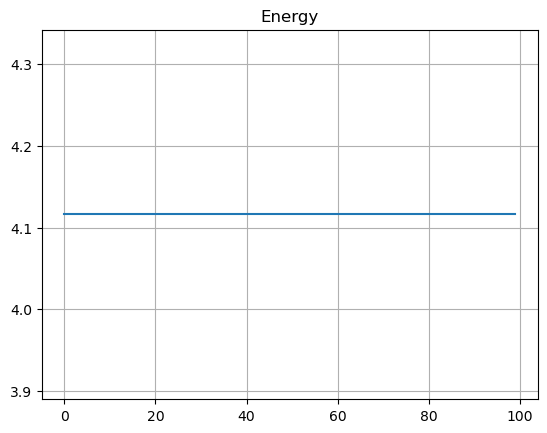

In [93]:
plt.plot(energies); plt.title('Energy'); plt.grid(); plt.show()

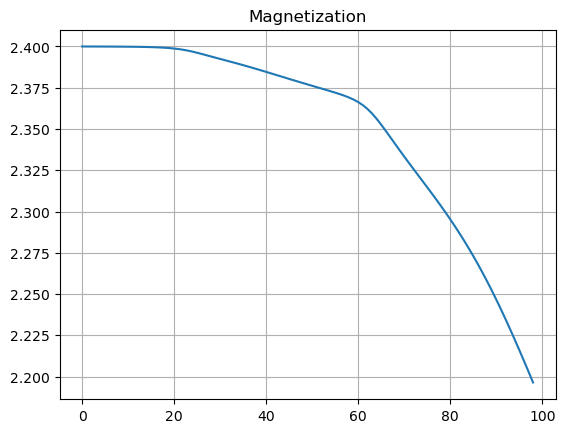

In [81]:
plt.plot(magnetizations); plt.title("Magnetization"); plt.grid(); plt.show()

In [64]:
import numpy as np
from scipy.optimize import root

Hm = H.to_matrix()

C = []
for i in range(nqubits):
    p = ["I"] * nqubits
    p[i] = "Y"
    C.append(
        SparsePauliOp(["".join(p)], coeffs=[1.0]).to_matrix()
    )

def constraints_of_lambda(lmbda):

    H_eff2 = Hm.copy()

    for a, Ck in zip(lmbda, C):
        H_eff2 += a * Ck

    eigvals, eigvecs = np.linalg.eigh(H_eff2)

    psi = eigvecs[:, 0]

    return np.array([
        np.real(
            np.vdot(
                psi,
                Ck @ psi
            )
        ) - target
        for Ck in C
    ])

sol = root(
    constraints_of_lambda,
    x0=np.zeros(nqubits)
)

print("lambdas =", sol.x)

H_eff2 = Hm.copy()

for a, Ck in zip(sol.x, C):
    H_eff2 += a * Ck

eigvals, eigvecs = np.linalg.eigh(H_eff2)

psi = eigvecs[:, 0]

energy = np.real(
    np.vdot(
        psi,
        Hm @ psi
    )
)

print("Constrained energy =", energy)

for i, Ck in enumerate(C):
    print(
        f"constraint {i}",
        np.real(
            np.vdot(
                psi,
                Ck @ psi
            )
        )
    )

lambdas = [-0.12996667 -0.16415694 -0.12996667 -0.12996667 -0.16415694 -0.12996667]
Constrained energy = -1.979913086041175
constraint 0 0.30000000000240035
constraint 1 0.2999999999973382
constraint 2 0.3000000000024
constraint 3 0.30000000000240074
constraint 4 0.29999999999733845
constraint 5 0.3000000000024005


In [66]:
evals = np.linalg.eigvalsh(
    H.to_matrix()
)

print("Exact spectrum")

print(np.round(evals,2))

Exact spectrum
[-2.11 -2.08 -1.45 -1.43 -1.21 -1.18 -1.18 -1.08 -0.98 -0.98 -0.91 -0.87
 -0.82 -0.7  -0.7  -0.64 -0.64 -0.62 -0.5  -0.48 -0.42 -0.41 -0.34 -0.28
 -0.25 -0.25 -0.25 -0.25 -0.15 -0.07 -0.04 -0.04  0.04  0.04  0.07  0.15
  0.25  0.25  0.25  0.25  0.28  0.34  0.41  0.42  0.48  0.5   0.62  0.64
  0.64  0.7   0.7   0.82  0.87  0.91  0.98  0.98  1.08  1.18  1.18  1.21
  1.43  1.45  2.08  2.11]
